In [3]:
from google.colab import files
uploaded = files.upload()  # opens a file picker, choose your zip

# Then unzip it
import zipfile
with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('dataset')

Saving archive.zip to archive.zip


In [4]:
import os
os.listdir('dataset')

['Face Mask Dataset']

In [5]:
os.listdir('dataset/Face Mask Dataset')

['Validation', 'Test', 'Train']

In [6]:
os.listdir('dataset/Face Mask Dataset/Train')

['WithoutMask', 'WithMask']

In [7]:
train_generator = train_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Validation',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

NameError: name 'train_datagen' is not defined

In [8]:
train_generator = train_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Validation',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # important for test set — keeps labels in order for evaluation later
)

NameError: name 'train_datagen' is not defined

In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

In [10]:
train_generator = train_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Validation',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical'
)

test_generator = val_datagen.flow_from_directory(
    'dataset/Face Mask Dataset/Test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 10000 images belonging to 2 classes.
Found 800 images belonging to 2 classes.
Found 992 images belonging to 2 classes.


In [11]:
print(train_generator.class_indices)

{'WithMask': 0, 'WithoutMask': 1}


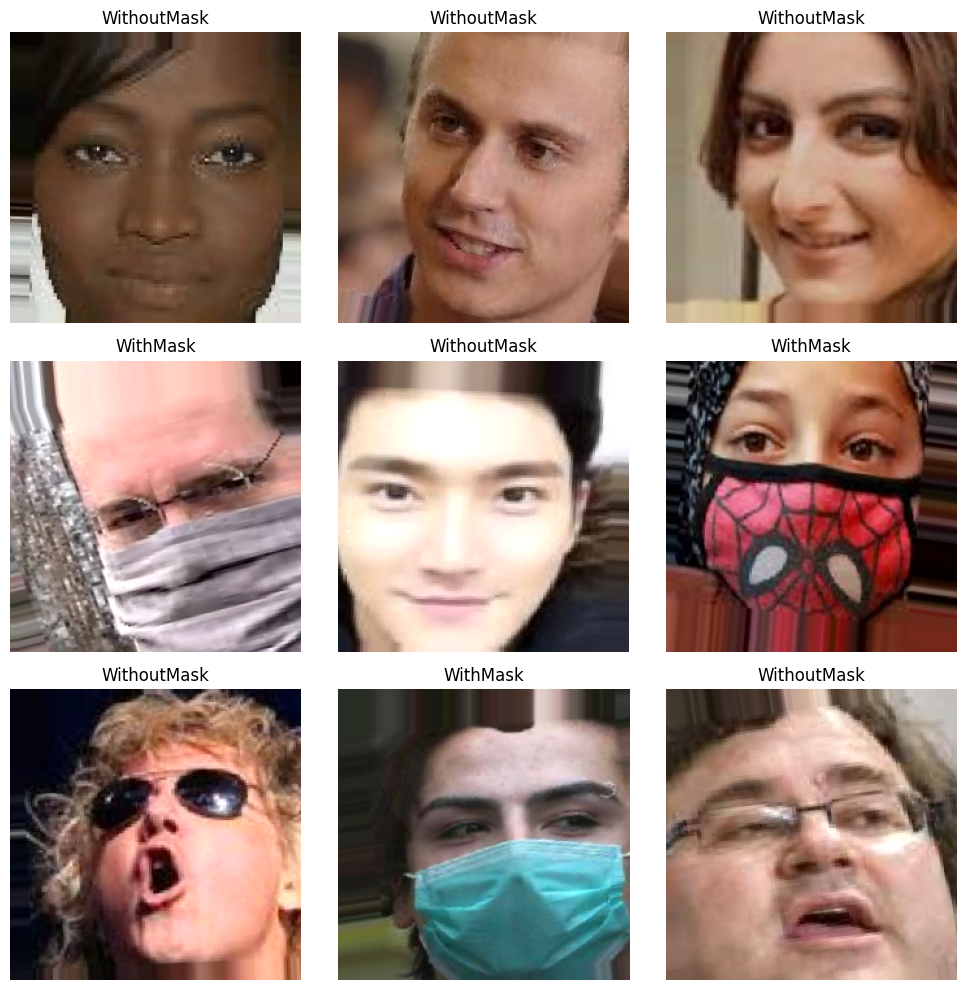

In [12]:
import matplotlib.pyplot as plt

images, labels = next(train_generator)
class_names = list(train_generator.class_indices.keys())

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    label_index = labels[i].argmax()
    plt.title(class_names[label_index])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# Load MobileNetV2 pretrained on ImageNet, without its original classification head
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,      # exclude ImageNet's 1000-class output layer
    weights='imagenet'
)

# Freeze the base model's layers - we don't want to retrain these yet
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [14]:
x = base_model.output
x = GlobalAveragePooling2D()(x)   # flattens feature maps into a vector
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)               # helps prevent overfitting
predictions = Dense(2, activation='softmax')(x)   # 2 classes: WithMask, WithoutMask

model = Model(inputs=base_model.input, outputs=predictions)

In [15]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [16]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
model.summary()

In [17]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 642s 2s/step - accuracy: 0.9731 - loss: 0.0735 - val_accuracy: 0.9925 - val_loss: 0.0214
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 623s 2s/step - accuracy: 0.9886 - loss: 0.0344 - val_accuracy: 0.9912 - val_loss: 0.0192
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 612s 2s/step - accuracy: 0.9890 - loss: 0.0331 - val_accuracy: 0.9925 - val_loss: 0.0218
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 610s 2s/step - accuracy: 0.9883 - loss: 0.0286 - val_accuracy: 0.9937 - val_loss: 0.0170
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 612s 2s/step - accuracy: 0.9902 - loss: 0.0283 - val_accuracy: 0.9937 - val_loss: 0.0186
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 609s 2s/step - accuracy: 0.9913 - loss: 0.0239 - val_accuracy: 0.9912 - val_loss: 0.0227
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 607s 2s/step - accuracy: 0.9931 - loss: 0.0215 - val_accuracy: 0.9800 - val_loss: 0.0493
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 610s 2s/step - accuracy: 0.9927 - loss: 0.0222 - val_accu

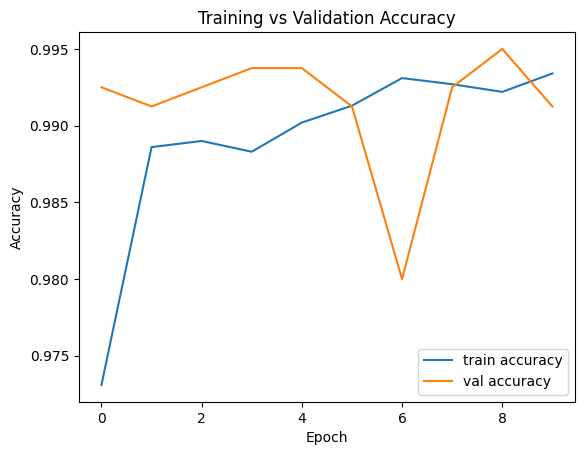

In [18]:
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training vs Validation Accuracy')
plt.show()

In [19]:
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

31/31 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.9919 - loss: 0.0228
Test Accuracy: 0.9919
Test Loss: 0.0228


31/31 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step


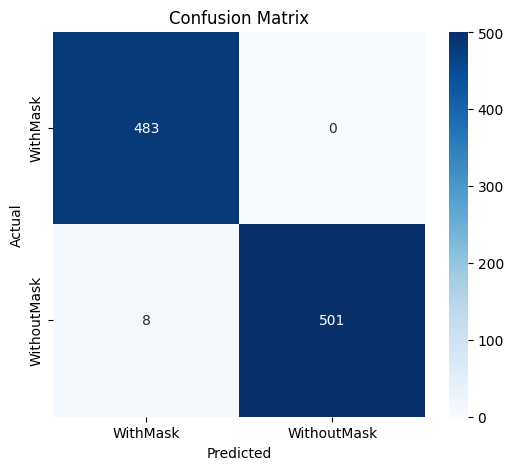

              precision    recall  f1-score   support

    WithMask       0.98      1.00      0.99       483
 WithoutMask       1.00      0.98      0.99       509

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



In [20]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Get predictions
predictions = model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes  # true labels, in order since shuffle=False

# Class names
class_names = list(test_generator.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Precision, recall, F1
print(classification_report(true_classes, predicted_classes, target_names=class_names))

In [21]:
model.save('mask_detector_model.h5')

# Optional: save to Google Drive so it survives runtime restarts
!cp mask_detector_model.h5 /content/drive/MyDrive/

cp: cannot create regular file '/content/drive/MyDrive/': No such file or directory


In [22]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
from google.colab import files
files.download('mask_detector_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
print(train_generator.class_indices)


{'WithMask': 0, 'WithoutMask': 1}
